# Corpus Analysis — English–Tagalog–Ilokano E-Governance Citizen Feedback

**Dataset:** Finalized annotated and preprocessed citizen-feedback workbook  
**Task:** Multilingual aspect-based sentiment analysis (ABSA), eventually using GLOT500-m  
**Scope of this notebook:** Reproducible descriptive corpus analysis, visualization, and summary tables. **No cleaning, relabeling, training, or train–test splitting is performed.**

**Unit of analysis matters:** A *comment* is a unique `comment_id` in `preprocessed_corpus`; an *aspect annotation* is a row in `preprocessed_aspect_annotations`. Several aspects (and potentially different sentiments) may occur in one comment.

## 1. Setup and load the finalized corpus

The workbook is read only. The notebook uses the two final preprocessed sheets as the authoritative analysis dataset. It also reads `raw` and `inclusion_exclusion` **only** to describe the collection-to-corpus flow.

In [ ]:
from pathlib import Path
from collections import Counter
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path('citizen_feedback_raw_v1 (2).xlsx')
if not DATA_FILE.exists():
    alternate = Path('/mnt/data') / DATA_FILE.name
    if alternate.exists():
        DATA_FILE = alternate
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot locate {DATA_FILE.name}. Place the Excel workbook beside the notebook, "
        "or set DATA_FILE to its full path."
    )

OUTPUT_DIR = Path('corpus_analysis_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 120)

# Selective loading avoids bringing the workbook's supporting/draft sheets into the analysis.
corpus = pd.read_excel(DATA_FILE, sheet_name='preprocessed_corpus', usecols='A:Y')
aspects = pd.read_excel(DATA_FILE, sheet_name='preprocessed_aspect_annotations', usecols='A:P')
raw = pd.read_excel(DATA_FILE, sheet_name='raw', usecols='A:H')
inclusion = pd.read_excel(DATA_FILE, sheet_name='inclusion_exclusion', usecols='A:J')

for frame in (corpus, aspects, raw, inclusion):
    frame.columns = frame.columns.astype(str).str.strip()
if 'comment_id' not in inclusion.columns:
    inclusion = inclusion.rename(columns={inclusion.columns[0]: 'comment_id'})

print('Workbook:', DATA_FILE.resolve())
print('Imported sheets: preprocessed_corpus, preprocessed_aspect_annotations, raw, inclusion_exclusion')
print(f'Initial worksheet sizes: corpus={len(corpus):,}, aspect rows={len(aspects):,}, raw={len(raw):,}')

Workbook: /mnt/data/citizen_feedback_raw_v1 (2).xlsx
Imported sheets: preprocessed_corpus, preprocessed_aspect_annotations, raw, inclusion_exclusion
Initial worksheet sizes: corpus=973, aspect rows=1,327, raw=1,131


## 2. Define the analytical dataset

This step creates **in-memory helper columns** for consistent summaries (e.g., reporting both `Ilocano` and `Ilokano` as `Ilokano`). The Excel file, original labels, and annotation IDs remain unchanged. Only valid `C`-numbered comment IDs are included in the reported dataset.

In [ ]:
def valid_id(frame):
    return frame['comment_id'].astype('string').str.strip().str.fullmatch(r'C\d{4,}', na=False)

corpus = corpus.loc[valid_id(corpus)].copy()
aspects = aspects.loc[valid_id(aspects)].copy()
raw = raw.loc[valid_id(raw)].copy()
inclusion = inclusion.loc[valid_id(inclusion)].copy()

for frame in (corpus, aspects, raw, inclusion):
    frame['comment_id'] = frame['comment_id'].astype('string').str.strip()

# Canonical fields are used for reporting, not as revisions to the annotation.
lang_col = 'primary_language_canonical' if 'primary_language_canonical' in corpus else 'primary_language'
cs_col = 'code_switched_canonical' if 'code_switched_canonical' in corpus else 'code_switched'
corpus['_language'] = (corpus[lang_col].fillna('Unspecified').astype(str)
                       .str.strip().replace({'Ilocano': 'Ilokano', '': 'Unspecified'}))
corpus['_code_switch'] = (corpus[cs_col].fillna('Unspecified').astype(str)
                          .str.strip().str.title().replace({'': 'Unspecified'}))
corpus['_model_text'] = corpus['model_text'].fillna('').astype(str)
corpus['_char_length'] = corpus['_model_text'].str.len()
corpus['_token_count'] = pd.to_numeric(corpus['token_count_full'], errors='coerce')
corpus['_token_count_filtered'] = pd.to_numeric(corpus['token_count_filtered'], errors='coerce')
corpus['_source'] = corpus['source_type'].fillna('Unspecified').astype(str).str.strip()
corpus['_topic'] = corpus['source_topic'].fillna('Unspecified').astype(str).str.strip()
corpus['_policy'] = corpus['legislation_or_policy'].fillna('Unspecified').astype(str).str.strip()

aspects['_sentiment'] = aspects['sentiment'].fillna('Unspecified').astype(str).str.strip().str.title()
code_from_field = aspects['aspect_code'].fillna('').astype(str).str.extract(r'(A\d{2})', expand=False)
code_from_category = aspects['aspect_category'].fillna('').astype(str).str.extract(r'(A\d{2})', expand=False)
aspects['_aspect_code'] = code_from_field.fillna(code_from_category).fillna('Unknown')
aspects['_aspect_label'] = aspects['aspect_category'].fillna('Unknown').astype(str).str.strip()

# Each aspect receives the language and code-switch labels of its source comment.
meta = corpus[['comment_id', '_language', '_code_switch', '_source', '_topic', '_policy']]
aspect_analysis = aspects.merge(meta, on='comment_id', how='left', validate='many_to_one')

print(f'Final corpus: {len(corpus):,} comments')
print(f'Final annotations: {len(aspects):,} aspect rows')
print(f'Unique annotated comments: {aspects.comment_id.nunique():,}')
print('Sentiment labels:', ', '.join(sorted(aspects['_sentiment'].unique())))

Final corpus: 973 comments
Final annotations: 1,327 aspect rows
Unique annotated comments: 973
Sentiment labels: Negative, Neutral, Positive


## 3. Corpus inventory and internal consistency

These are **descriptive checks**, not proposals to change a finalized corpus. They let the research team accurately report the denominator in its methodology section.

,Stage,Count
0,Collected raw comments,1131
1,Marked Include (initial review),988
2,Marked Exclude (initial review),143
3,Final corpus comments,973
4,Final aspect annotations,1327
5,Unique comments with aspects,973


,Metric,Count
0,Duplicate comment IDs in final corpus,0
1,Duplicate aspect IDs,0
2,Aspect rows with missing source comment,0
3,Corpus comments without aspects,0
4,Blank model texts,0
5,Blank sentiment labels,0


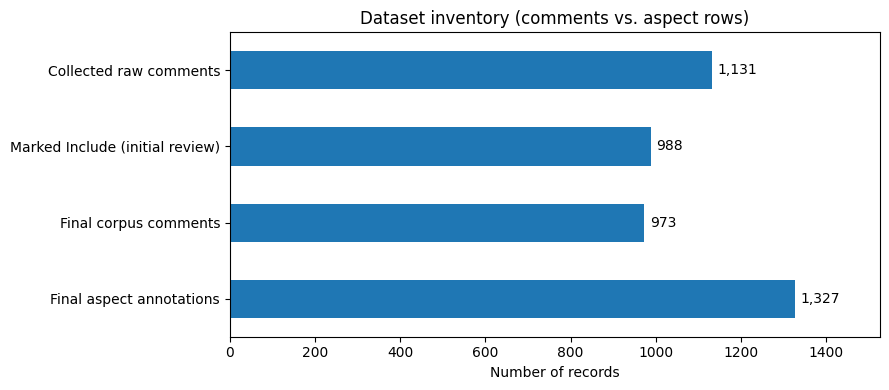

In [ ]:
inc_column = next((c for c in inclusion.columns if c.casefold().replace(' ', '') == 'include/exclude'), None)
if inc_column is None:
    inc_column = 'Include/Exclude'

inclusion_status = inclusion[inc_column].fillna('').astype(str).str.strip().str.casefold()
included_n = int(inclusion_status.eq('include').sum())
excluded_n = int(inclusion_status.eq('exclude').sum())

inventory = pd.DataFrame({
    'Stage': ['Collected raw comments', 'Marked Include (initial review)',
              'Marked Exclude (initial review)', 'Final corpus comments',
              'Final aspect annotations', 'Unique comments with aspects'],
    'Count': [len(raw), included_n, excluded_n, len(corpus), len(aspects), aspects.comment_id.nunique()]
})
display(inventory)

integrity = pd.DataFrame({
    'Metric': ['Duplicate comment IDs in final corpus', 'Duplicate aspect IDs',
               'Aspect rows with missing source comment', 'Corpus comments without aspects',
               'Blank model texts', 'Blank sentiment labels'],
    'Count': [int(corpus.comment_id.duplicated().sum()),
              int(aspects.aspect_id.duplicated().sum()),
              int((~aspects.comment_id.isin(corpus.comment_id)).sum()),
              int((~corpus.comment_id.isin(aspects.comment_id)).sum()),
              int(corpus['_model_text'].str.strip().eq('').sum()),
              int(aspects['_sentiment'].eq('Unspecified').sum())]
})
display(integrity)

fig, ax = plt.subplots(figsize=(9, 4))
stage_counts = inventory.set_index('Stage').loc[
    ['Collected raw comments', 'Marked Include (initial review)', 'Final corpus comments', 'Final aspect annotations'], 'Count'
]
stage_counts.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set(xlabel='Number of records', ylabel='', title='Dataset inventory (comments vs. aspect rows)')
for index, val in enumerate(stage_counts):
    ax.text(val + max(stage_counts)*0.01, index, f'{val:,}', va='center')
ax.set_xlim(0, max(stage_counts)*1.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_corpus_inventory.png', dpi=170)
plt.show()

## 4. Language composition and code-switching

Primary-language figures count **comments**. A comment labeled `Mixed` is shown separately. The `languages` field lists languages present and is analyzed as combinations, not treated as a single primary-language label.

,Primary language,Count,Percentage
0,Tagalog,470,48.30
1,English,230,23.64
2,Ilokano,167,17.16
3,Mixed,106,10.89


,Code-switched,Count,Percentage
0,No,565,58.07
1,Yes,408,41.93


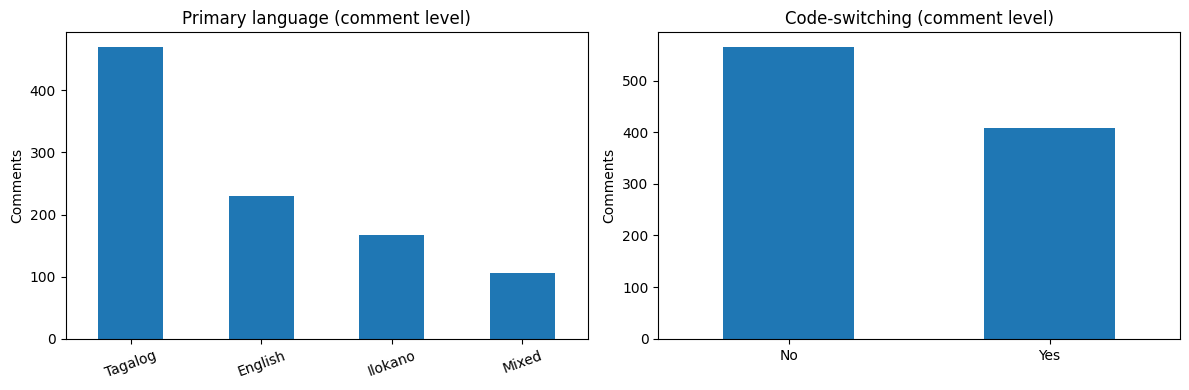

Language combinations:


,Languages present,Count,Percentage
0,"English, Tagalog",340,34.94
1,Tagalog,263,27.03
2,English,152,15.62
3,Ilokano,95,9.76
4,"English, Ilokano",50,5.14
5,"English, Tagalog, Ilokano",41,4.21
6,"Tagalog, Ilokano",29,2.98
7,"Ilokano, English",1,0.10
8,"Tagalog, English",1,0.10
9,"English, Ilokano, Tagalog",1,0.10


In [ ]:
def counts_table(values, index_title):
    counts = values.value_counts(dropna=False)
    result = counts.rename_axis(index_title).reset_index(name='Count')
    result['Percentage'] = (100 * result['Count'] / result['Count'].sum()).round(2)
    return result

language_dist = counts_table(corpus['_language'], 'Primary language')
cs_dist = counts_table(corpus['_code_switch'], 'Code-switched')
display(language_dist)
display(cs_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
language_dist.set_index('Primary language')['Count'].plot.bar(ax=axes[0])
axes[0].set(xlabel='', ylabel='Comments', title='Primary language (comment level)')
axes[0].tick_params(axis='x', rotation=20)
cs_dist.set_index('Code-switched')['Count'].plot.bar(ax=axes[1])
axes[1].set(xlabel='', ylabel='Comments', title='Code-switching (comment level)')
axes[1].tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '02_language_and_codeswitching.png', dpi=170)
plt.show()

language_combos = counts_table(
    corpus['languages'].fillna('Unspecified').astype(str).str.strip(), 'Languages present'
)
print('Language combinations:')
display(language_combos)

## 5. Text lengths, token counts, and lexical richness

`token_count_full` and `tokenized_text_full` come from your preprocessing pipeline, **not** from the GLOT500-m subword tokenizer. The filtered-token fields represent the already-filtered exploratory representation; for fine-tuning, consider the full `model_text` instead of filtered text.

,Characters (model_text),Full tokens,Filtered tokens
count,973.00,973.00,973.00
mean,143.65,25.01,19.00
std,144.58,25.15,18.14
min,4.00,1.00,1.00
25%,57.00,10.00,8.00
50%,105.00,18.00,14.00
75%,175.00,31.00,23.00
90%,307.00,54.00,39.80
95%,391.40,67.00,49.00
99%,642.64,118.28,85.28


,Measure,Value
0,Full token occurrences,24333.0000
1,Unique full tokens,5630.0000
2,Corpus-level full type–token ratio,0.2314
3,Filtered token occurrences,18483.0000
4,Unique filtered tokens,5558.0000
5,Corpus-level filtered type–token ratio,0.3007


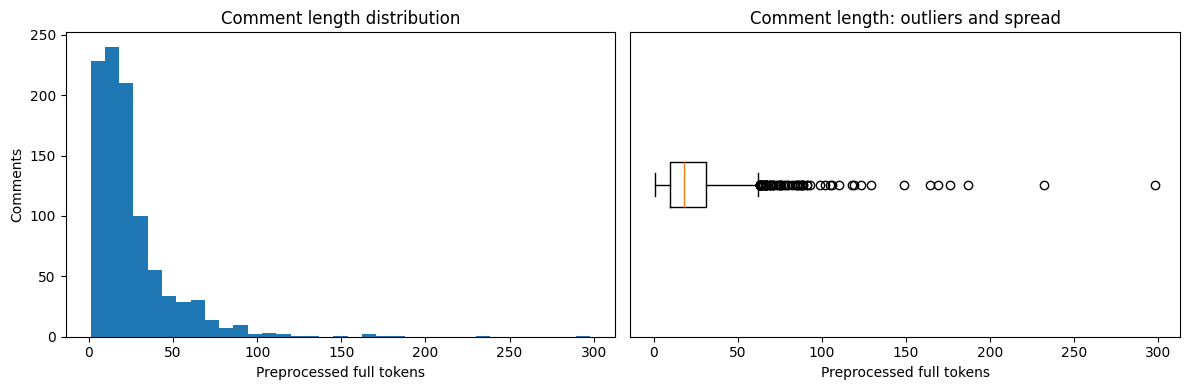

,count,mean,median,max
Primary language,,,,
English,230,31.27,22.5,298
Ilokano,167,19.68,17.0,119
Mixed,106,38.61,28.0,232
Tagalog,470,20.77,15.0,169


In [ ]:
length_summary = corpus[['_char_length', '_token_count', '_token_count_filtered']].describe(
    percentiles=[.25, .50, .75, .90, .95, .99]
).round(2).rename(columns={
    '_char_length': 'Characters (model_text)',
    '_token_count': 'Full tokens',
    '_token_count_filtered': 'Filtered tokens'
})
display(length_summary)

full_tokens = [tok for v in corpus['tokenized_text_full'].fillna('')
               for tok in str(v).split() if tok]
filtered_tokens = [tok for v in corpus['tokenized_text_filtered'].fillna('')
                   for tok in str(v).split() if tok]
lexical_summary = pd.DataFrame({
    'Measure': ['Full token occurrences', 'Unique full tokens', 'Corpus-level full type–token ratio',
                'Filtered token occurrences', 'Unique filtered tokens', 'Corpus-level filtered type–token ratio'],
    'Value': [len(full_tokens), len(set(full_tokens)),
              round(len(set(full_tokens)) / len(full_tokens), 4) if full_tokens else np.nan,
              len(filtered_tokens), len(set(filtered_tokens)),
              round(len(set(filtered_tokens)) / len(filtered_tokens), 4) if filtered_tokens else np.nan]
})
display(lexical_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(corpus['_token_count'].dropna(), bins=35)
axes[0].set(xlabel='Preprocessed full tokens', ylabel='Comments', title='Comment length distribution')
axes[1].boxplot(corpus['_token_count'].dropna(), vert=False)
axes[1].set(xlabel='Preprocessed full tokens', yticks=[], title='Comment length: outliers and spread')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_text_lengths.png', dpi=170)
plt.show()

# A language-specific comparison is descriptive, not a fair cross-language lexical-diversity test.
length_by_language = (corpus.groupby('_language')['_token_count']
                      .agg(['count','mean','median','max']).round(2)
                      .rename_axis('Primary language'))
display(length_by_language)

## 6. Most frequent words and bigrams

These counts use the **existing** `tokenized_text_filtered` field, so they reflect its filtering rules. Common function words or platform-specific vocabulary may remain in a multilingual dataset. A frequency chart is descriptive, not a sentiment lexicon.

,Token,Frequency
0,na,558
1,baguio,212
2,lang,194
3,yung,174
4,po,155
5,may,150
6,pa,133
7,naman,133
8,da,127
9,hindi,126


,Bigram,Frequency
0,na yan,23
1,public market,21
2,lalo na,20
3,na lang,19
4,na may,17
5,baguio city,17
6,na hindi,13
7,pa rin,13
8,naman po,12
9,di naman,12


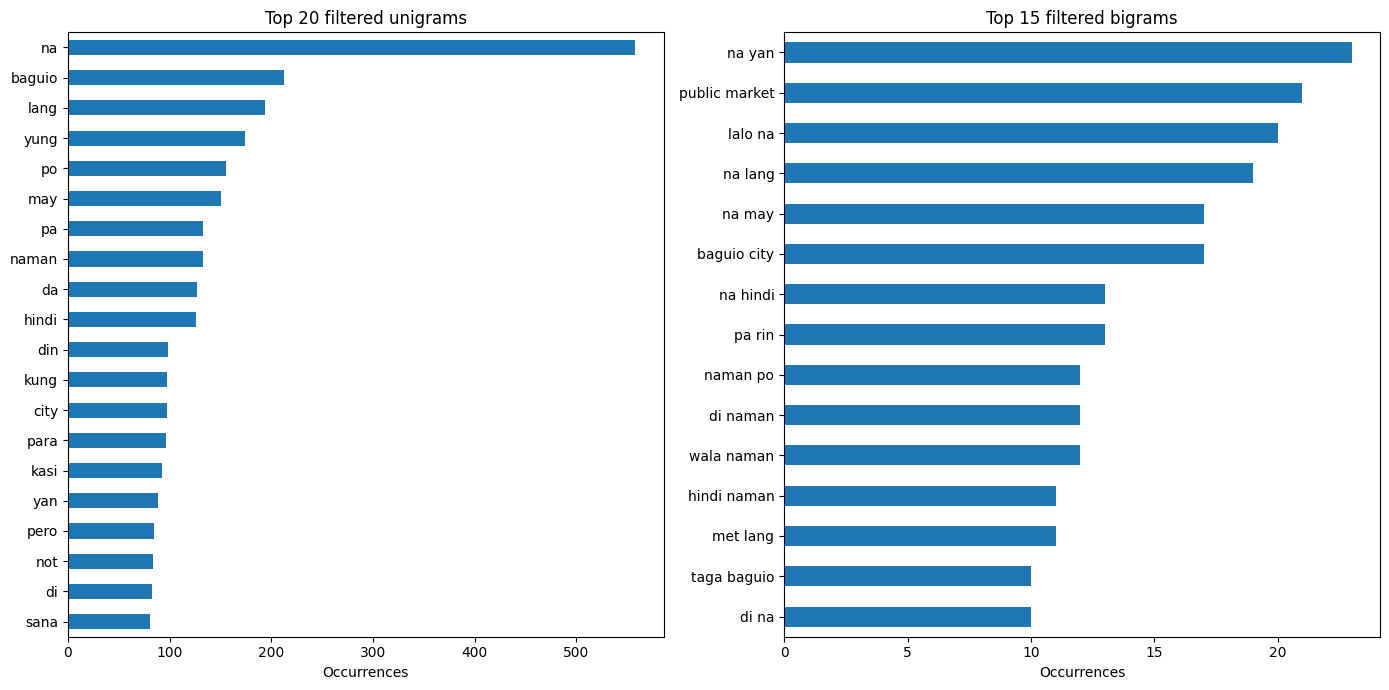

In [ ]:
unigram_counts = Counter(filtered_tokens)
word_top = pd.DataFrame(unigram_counts.most_common(25), columns=['Token','Frequency'])
display(word_top)

# Bigrams are formed within each comment only; they do not cross document boundaries.
bigram_counts = Counter()
for text in corpus['tokenized_text_filtered'].fillna(''):
    words = str(text).split()
    bigram_counts.update(zip(words, words[1:]))
bigram_top = pd.DataFrame(
    [(' '.join(bg), count) for bg, count in bigram_counts.most_common(20)],
    columns=['Bigram', 'Frequency']
)
display(bigram_top)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
word_top.iloc[:20].iloc[::-1].set_index('Token')['Frequency'].plot.barh(ax=axes[0])
axes[0].set(xlabel='Occurrences', ylabel='', title='Top 20 filtered unigrams')
bigram_top.iloc[:15].iloc[::-1].set_index('Bigram')['Frequency'].plot.barh(ax=axes[1])
axes[1].set(xlabel='Occurrences', ylabel='', title='Top 15 filtered bigrams')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '04_top_ngrams.png', dpi=170)
plt.show()

## 7. Source platform, topic, and policy coverage

This documents **where the dataset came from**, rather than estimating the views of all citizens. Uneven platform or policy coverage can affect model generalization.

,Source platform,Count,Percentage
0,Facebook,505,51.90
1,Reddit,189,19.42
2,Threads,142,14.59
3,Tiktok,137,14.08


,Source topic,Count,Percentage
0,Waste Management,232,23.84
1,Public Safety,141,14.49
2,Road Safety / Pedestrian Safety,71,7.30
3,Traffic & Mobility,59,6.06
4,Local–Tourist Concerns,58,5.96
5,Pet Ownership,51,5.24
6,Overtourism & Tourism Management,36,3.70
7,Noise Regulation,35,3.60
8,Leadership & Political Accountability\nTranspo...,28,2.88
9,Transportation and Traffic,28,2.88


Policy counts (top 20):


,Legislation or policy,Count,Percentage
0,Curfew for Minors Ordinance,134,13.77
1,Anti-Littering Ordinance,95,9.76
2,Anti-Distracted Walking Ordinance,71,7.30
3,Revised Garbage Fees,71,7.30
4,Plastic and Styrofoam Ban,67,6.89
5,Tourist/Traffic Regulation,58,5.96
6,Pet Ownership Ordinance,51,5.24
7,King of the Road Ordinance,47,4.83
8,Traffic Management & Transport Policy,44,4.52
9,Silent Night Ordinance,35,3.60


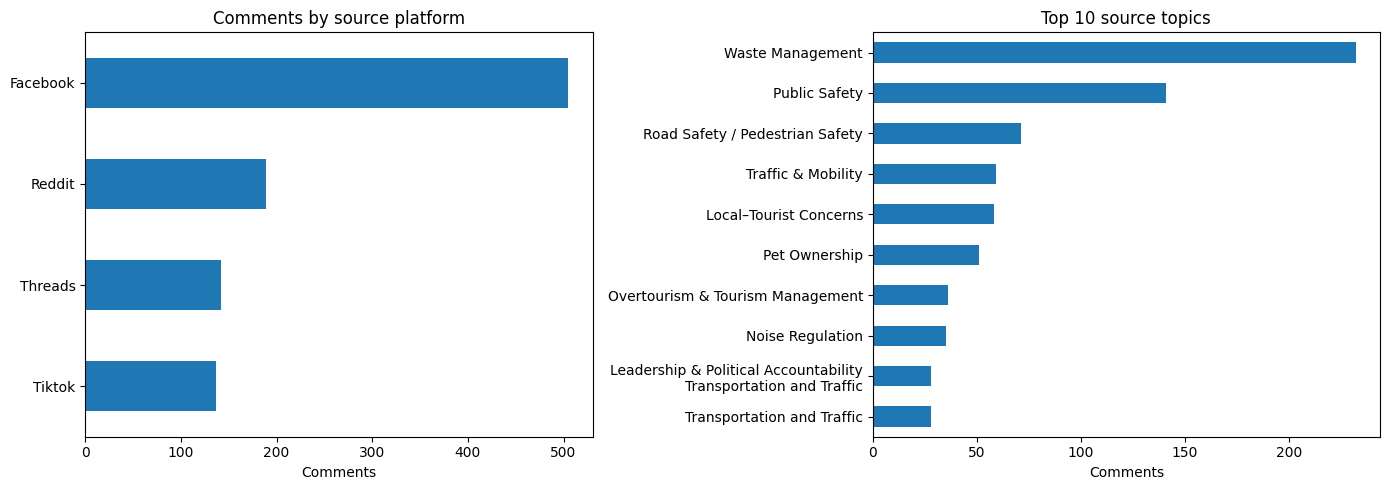

In [ ]:
platform_dist = counts_table(corpus['_source'], 'Source platform')
topic_dist = counts_table(corpus['_topic'], 'Source topic')
policy_dist = counts_table(corpus['_policy'], 'Legislation or policy')
display(platform_dist)
display(topic_dist)
print('Policy counts (top 20):')
display(policy_dist.head(20))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
platform_dist.iloc[::-1].set_index('Source platform')['Count'].plot.barh(ax=axes[0])
axes[0].set(xlabel='Comments', ylabel='', title='Comments by source platform')
topic_dist.head(10).iloc[::-1].set_index('Source topic')['Count'].plot.barh(ax=axes[1])
axes[1].set(xlabel='Comments', ylabel='', title='Top 10 source topics')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_sources_and_topics.png', dpi=170)
plt.show()

## 8. Aspect annotation density

For ABSA, aspect *rows* are not interchangeable with unique comments. This section measures how many targets are annotated per comment and how often a comment contains several sentiment labels.

,Aspects per comment,Count,Percentage
0,1,708,72.76
1,2,203,20.86
2,3,44,4.52
3,4,10,1.03
4,5,7,0.72
5,6,1,0.10


Average aspects per comment: 1.36
Comments with more than one aspect: 265 (27.2%)
Comments with different aspect sentiments: 135
Comments containing both positive and negative aspects: 88


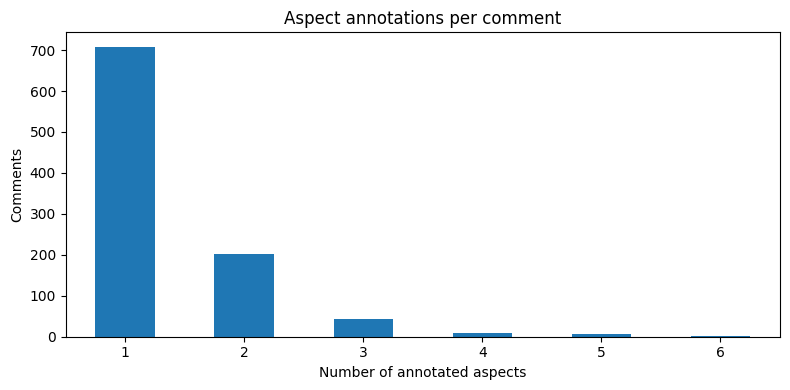

In [ ]:
aspect_per_comment = aspects.groupby('comment_id').size().rename('Aspect count')
density_dist = counts_table(aspect_per_comment, 'Aspects per comment').sort_values('Aspects per comment')
display(density_dist)

sentiments_per_comment = aspects.groupby('comment_id')['_sentiment'].agg(lambda s: set(s))
multi_aspect_comments = int((aspect_per_comment > 1).sum())
multiple_sentiments = int(sentiments_per_comment.apply(lambda s: len(s) > 1).sum())
pos_and_neg = int(sentiments_per_comment.apply(lambda s: {'Positive','Negative'}.issubset(s)).sum())

print(f'Average aspects per comment: {aspect_per_comment.mean():.2f}')
print(f'Comments with more than one aspect: {multi_aspect_comments:,} ({100*multi_aspect_comments/len(corpus):.1f}%)')
print(f'Comments with different aspect sentiments: {multiple_sentiments:,}')
print(f'Comments containing both positive and negative aspects: {pos_and_neg:,}')

fig, ax = plt.subplots(figsize=(8, 4))
density_dist.set_index('Aspects per comment')['Count'].plot.bar(ax=ax)
ax.set(xlabel='Number of annotated aspects', ylabel='Comments', title='Aspect annotations per comment')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '06_aspects_per_comment.png', dpi=170)
plt.show()

## 9. Sentiment balance (aspect level)

**Denominator:** Total aspect annotations (not comments). Macro-averaged F1 is recommended for the later model evaluation because the three classes may not have equal support.

,Sentiment,Count,Percentage
0,Negative,766,57.72
1,Positive,309,23.29
2,Neutral,252,18.99


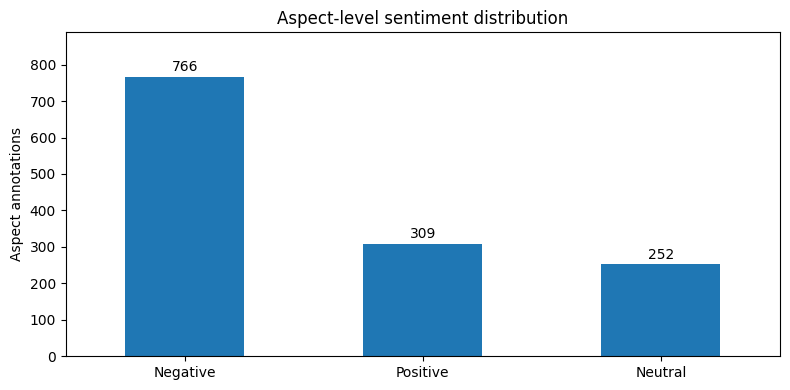

In [ ]:
order = ['Negative', 'Positive', 'Neutral']
sentiment_dist = counts_table(aspects['_sentiment'], 'Sentiment')
sentiment_dist['_sort'] = sentiment_dist['Sentiment'].map({s:i for i,s in enumerate(order)}).fillna(99)
sentiment_dist = sentiment_dist.sort_values('_sort').drop(columns='_sort')
display(sentiment_dist)

fig, ax = plt.subplots(figsize=(8, 4))
sentiment_dist.set_index('Sentiment')['Count'].plot.bar(ax=ax)
ax.set(xlabel='', ylabel='Aspect annotations', title='Aspect-level sentiment distribution')
ax.tick_params(axis='x', rotation=0)
for i, val in enumerate(sentiment_dist['Count']):
    ax.text(i, val + max(sentiment_dist['Count']) * .02, f'{val:,}', ha='center')
ax.set_ylim(top=max(sentiment_dist['Count']) * 1.16)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '07_sentiment_distribution.png', dpi=170)
plt.show()

## 10. Aspect-category coverage and sentiment by aspect

The A01–A11 taxonomy identifies the topic of **each expressed concern**, not a global sentiment label. The heatmap shows the **within-category percentage** of Positive, Negative, and Neutral annotation rows.

,Aspect code,Aspect category,Count,Percentage
0,A01,A01 — Policy Benefits and Impact,153,11.53
1,A02,A02 — Implementation and Enforcement,247,18.61
2,A03,"A03 — Cost, Fees and Penalties",131,9.87
3,A04,A04 — Accessibility and Convenience,100,7.54
4,A05,A05 — Fairness and Inclusivity,99,7.46
5,A06,A06 — Rules and Policy Provisions,185,13.94
6,A07,A07 — Government Administration and Responsive...,188,14.17
7,A08,A08 — Public Safety and Security,66,4.97
8,A09,A09 — Environmental Impact,51,3.84
9,A10,A10 — Traffic and Transportation Impact,96,7.23


Aspect category × sentiment (counts):


_sentiment,Negative,Positive,Neutral
_aspect_code,,,
A01,49,89,15
A02,111,69,67
A03,96,18,17
A04,61,16,23
A05,78,16,5
A06,58,49,78
A07,138,16,34
A08,39,21,6
A09,42,7,2


Aspect category × sentiment (row percentages):


_sentiment,Negative,Positive,Neutral
_aspect_code,,,
A01,32.0,58.2,9.8
A02,44.9,27.9,27.1
A03,73.3,13.7,13.0
A04,61.0,16.0,23.0
A05,78.8,16.2,5.1
A06,31.4,26.5,42.2
A07,73.4,8.5,18.1
A08,59.1,31.8,9.1
A09,82.4,13.7,3.9


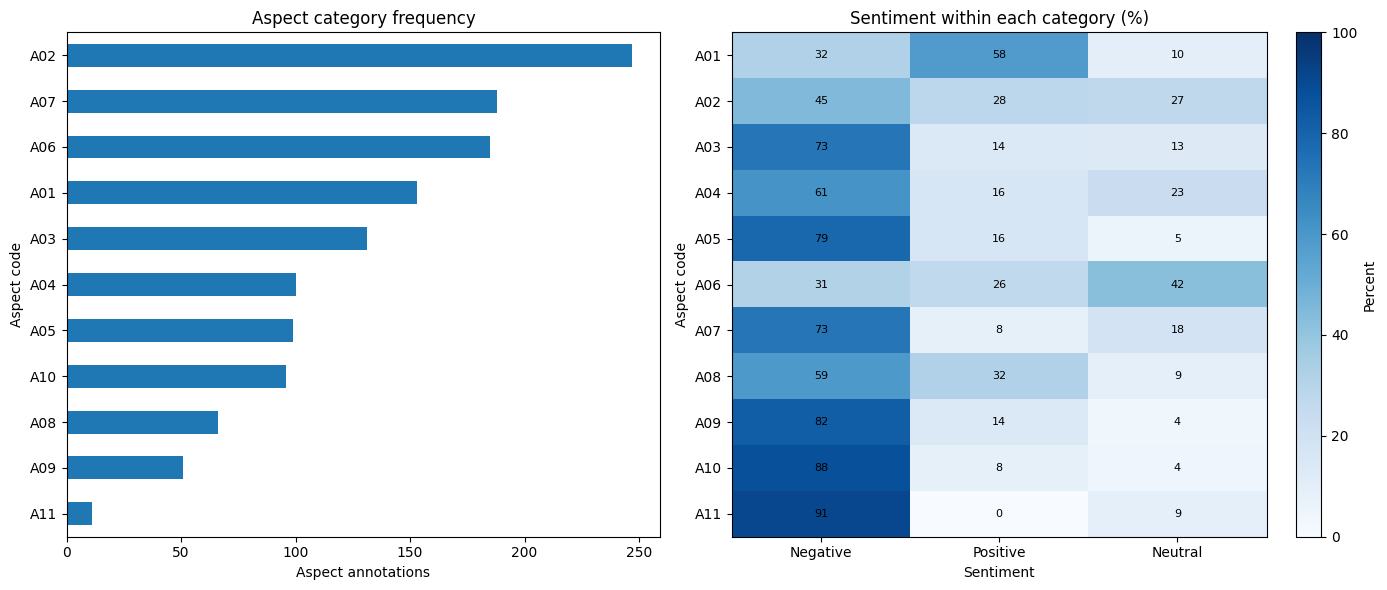

In [ ]:
aspect_dist = (aspects.groupby(['_aspect_code','_aspect_label']).size()
               .rename('Count').reset_index()
               .sort_values(['_aspect_code', '_aspect_label']))
aspect_dist['Percentage'] = (100 * aspect_dist['Count'] / len(aspects)).round(2)
display(aspect_dist.rename(columns={'_aspect_code':'Aspect code','_aspect_label':'Aspect category'}))

category_sentiment = pd.crosstab(aspects['_aspect_code'], aspects['_sentiment'])
category_sentiment = category_sentiment.reindex(columns=order, fill_value=0).sort_index()
category_sentiment_pct = category_sentiment.div(category_sentiment.sum(axis=1), axis=0).mul(100).fillna(0).round(1)
print('Aspect category × sentiment (counts):')
display(category_sentiment)
print('Aspect category × sentiment (row percentages):')
display(category_sentiment_pct)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
aspect_dist.sort_values('Count').plot.barh(x='_aspect_code', y='Count', ax=axes[0], legend=False)
axes[0].set(xlabel='Aspect annotations', ylabel='Aspect code', title='Aspect category frequency')
heat = axes[1].imshow(category_sentiment_pct.to_numpy(), aspect='auto', cmap='Blues', vmin=0, vmax=100)
axes[1].set_xticks(range(len(category_sentiment_pct.columns)), category_sentiment_pct.columns)
axes[1].set_yticks(range(len(category_sentiment_pct.index)), category_sentiment_pct.index)
axes[1].set(title='Sentiment within each category (%)', xlabel='Sentiment', ylabel='Aspect code')
for i in range(category_sentiment_pct.shape[0]):
    for j in range(category_sentiment_pct.shape[1]):
        axes[1].text(j, i, f'{category_sentiment_pct.iat[i,j]:.0f}', ha='center', va='center', fontsize=8)
fig.colorbar(heat, ax=axes[1], label='Percent', fraction=0.05)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '08_aspects_by_sentiment.png', dpi=170)
plt.show()

## 11. Sentiment by primary language and code-switching

These cross-tabs count **aspect annotations** with the language and code-switching status inherited from their corresponding comment. For example, a comment containing three annotated aspects contributes three rows to the language–sentiment table.

Primary language × sentiment (aspect counts):


_sentiment,Negative,Positive,Neutral
_language,,,
English,201,111,51
Ilokano,108,29,48
Mixed,112,41,16
Tagalog,345,128,137


Primary language × sentiment (within-language percentages):


_sentiment,Negative,Positive,Neutral
_language,,,
English,55.4,30.6,14.0
Ilokano,58.4,15.7,25.9
Mixed,66.3,24.3,9.5
Tagalog,56.6,21.0,22.5


Code-switching × sentiment (aspect counts):


_sentiment,Negative,Positive,Neutral
_code_switch,,,
No,360,166,171
Yes,406,143,81


Code-switching × sentiment (within-group percentages):


_sentiment,Negative,Positive,Neutral
_code_switch,,,
No,51.6,23.8,24.5
Yes,64.4,22.7,12.9


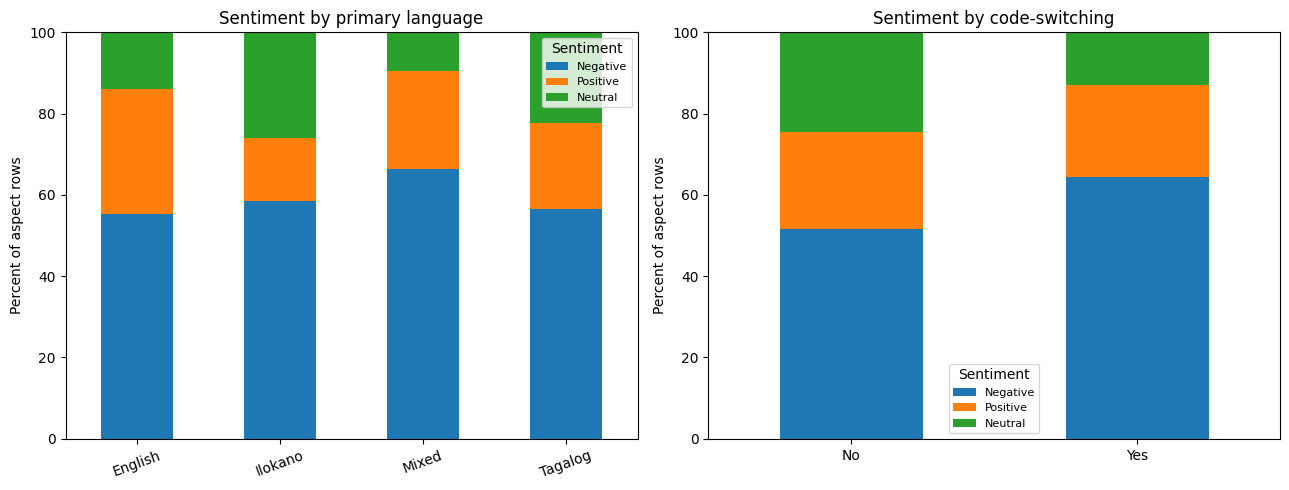

In [ ]:
language_sentiment = pd.crosstab(aspect_analysis['_language'], aspect_analysis['_sentiment']).reindex(columns=order, fill_value=0)
language_sentiment_pct = language_sentiment.div(language_sentiment.sum(axis=1), axis=0).mul(100).fillna(0).round(1)
cs_sentiment = pd.crosstab(aspect_analysis['_code_switch'], aspect_analysis['_sentiment']).reindex(columns=order, fill_value=0)
cs_sentiment_pct = cs_sentiment.div(cs_sentiment.sum(axis=1), axis=0).mul(100).fillna(0).round(1)

print('Primary language × sentiment (aspect counts):')
display(language_sentiment)
print('Primary language × sentiment (within-language percentages):')
display(language_sentiment_pct)
print('Code-switching × sentiment (aspect counts):')
display(cs_sentiment)
print('Code-switching × sentiment (within-group percentages):')
display(cs_sentiment_pct)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
language_sentiment_pct.plot.bar(stacked=True, ax=axes[0])
axes[0].set(xlabel='', ylabel='Percent of aspect rows', title='Sentiment by primary language')
axes[0].tick_params(axis='x', rotation=20)
cs_sentiment_pct.plot.bar(stacked=True, ax=axes[1])
axes[1].set(xlabel='', ylabel='Percent of aspect rows', title='Sentiment by code-switching')
axes[1].tick_params(axis='x', rotation=0)
for ax in axes:
    ax.set_ylim(0, 100)
    ax.legend(title='Sentiment', fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '09_sentiment_by_language_switching.png', dpi=170)
plt.show()

## 12. Coverage by platform and policy topic

Aspect sentiment proportions can vary by source platform and topic. These comparisons are descriptive and may reflect sampling and topic composition—not causal effects of the platform or policy.

_sentiment,Negative,Positive,Neutral
_source,,,
Facebook,47.6,22.9,29.5
Reddit,69.4,22.3,8.3
Threads,63.8,25.5,10.6
Tiktok,67.2,23.3,9.4


Most represented topics (aspect-level counts and negative proportion):


_sentiment,Negative,Positive,Neutral,Total aspects,Negative %
_topic,,,,,
Waste Management,137,54,72,263,52.1
Public Safety,34,49,73,156,21.8
Pet Ownership,68,40,9,117,58.1
Road Safety / Pedestrian Safety,55,4,22,81,67.9
Local–Tourist Concerns,58,13,3,74,78.4
Traffic & Mobility,46,12,9,67,68.7
Overtourism & Tourism Management,39,18,2,59,66.1
Public Market & Local Economy,39,17,2,58,67.2
Leadership & Political Accountability\nTransportation and Traffic,26,19,1,46,56.5


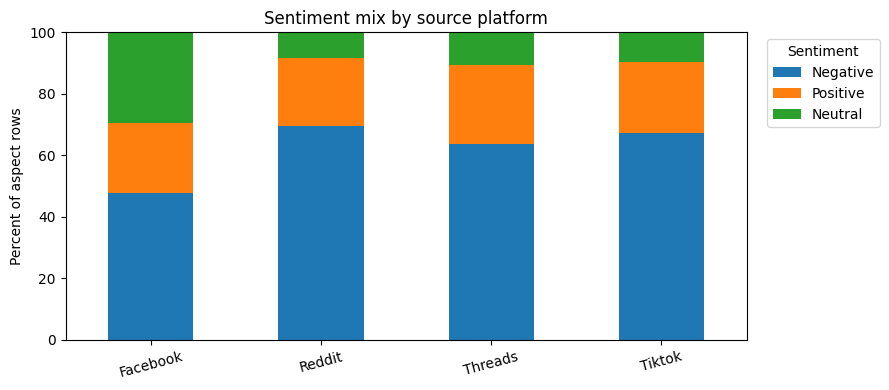

In [ ]:
source_sentiment = pd.crosstab(aspect_analysis['_source'], aspect_analysis['_sentiment']).reindex(columns=order, fill_value=0)
source_sentiment_pct = source_sentiment.div(source_sentiment.sum(axis=1), axis=0).mul(100).fillna(0).round(1)

topic_sentiment = pd.crosstab(aspect_analysis['_topic'], aspect_analysis['_sentiment']).reindex(columns=order, fill_value=0)
topic_sentiment['Total aspects'] = topic_sentiment.sum(axis=1)
topic_sentiment['Negative %'] = (100 * topic_sentiment['Negative'] / topic_sentiment['Total aspects'].replace(0, np.nan)).round(1)

display(source_sentiment_pct)
print('Most represented topics (aspect-level counts and negative proportion):')
display(topic_sentiment.sort_values('Total aspects', ascending=False).head(12))

fig, ax = plt.subplots(figsize=(9, 4))
source_sentiment_pct.plot.bar(stacked=True, ax=ax)
ax.set(xlabel='', ylabel='Percent of aspect rows', ylim=(0,100), title='Sentiment mix by source platform')
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Sentiment', bbox_to_anchor=(1.02,1), loc='upper left')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '10_sentiment_by_source.png', dpi=170)
plt.show()

## 13. Report-ready summary

This section turns the above calculations into an automatically updated numerical summary. Use these numbers in a methodology/results chapter, with your own interpretation and caveats.

In [ ]:
main_sentiment = sentiment_dist.loc[sentiment_dist['Count'].idxmax()]
main_language = language_dist.loc[language_dist['Count'].idxmax()]
main_source = platform_dist.loc[platform_dist['Count'].idxmax()]
main_aspect = aspect_dist.loc[aspect_dist['Count'].idxmax()]
switched = int(corpus['_code_switch'].eq('Yes').sum())

summary_lines = [
    f'The finalized corpus contains {len(corpus):,} unique comments and {len(aspects):,} aspect annotations.',
    f'The largest primary-language group is {main_language["Primary language"]} '
    f'({main_language["Count"]:,} comments; {main_language["Percentage"]:.1f}%).',
    f'Code-switched comments account for {switched:,}/{len(corpus):,} '
    f'({100*switched/len(corpus):.1f}%).',
    f'The most frequent sentiment is {main_sentiment["Sentiment"]} '
    f'({main_sentiment["Count"]:,} of {len(aspects):,} annotations; '
    f'{main_sentiment["Percentage"]:.1f}%).',
    f'The most frequent aspect category is {main_aspect["_aspect_code"]} '
    f'({int(main_aspect["Count"]):,} annotations).',
    f'There are {multi_aspect_comments:,} comments with multiple annotated aspects and '
    f'{multiple_sentiments:,} comments with more than one sentiment label.',
    f'The largest source platform is {main_source["Source platform"]} '
    f'({main_source["Count"]:,} comments; {main_source["Percentage"]:.1f}%).',
    f'The median text length is {corpus["_token_count"].median():.0f} full tokens; '
    f'the mean is {corpus["_token_count"].mean():.1f}.',
]
for sentence in summary_lines:
    print('• ' + sentence)

report_md = '# Corpus analysis — descriptive findings\n\n' + '\n\n'.join(summary_lines) + '\n'
(OUTPUT_DIR / 'corpus_analysis_summary.md').write_text(report_md, encoding='utf-8')

• The finalized corpus contains 973 unique comments and 1,327 aspect annotations.
• The largest primary-language group is Tagalog (470 comments; 48.3%).
• Code-switched comments account for 408/973 (41.9%).
• The most frequent sentiment is Negative (766 of 1,327 annotations; 57.7%).
• The most frequent aspect category is A02 (247 annotations).
• There are 265 comments with multiple annotated aspects and 135 comments with more than one sentiment label.
• The largest source platform is Facebook (505 comments; 51.9%).
• The median text length is 18 full tokens; the mean is 25.0.


616

## 14. Export summary tables

Tables are exported for the research paper or presentation. **Only derived outputs** go into the output directory; no raw or annotated entries are modified. The code does not create a train, validation, or test split.

In [ ]:
tables = {
    'inventory': inventory,
    'integrity_snapshot': integrity,
    'primary_language_distribution': language_dist,
    'code_switch_distribution': cs_dist,
    'language_combinations': language_combos,
    'text_length_summary': length_summary,
    'lexical_summary': lexical_summary,
    'top_unigrams': word_top,
    'top_bigrams': bigram_top,
    'source_distribution': platform_dist,
    'topic_distribution': topic_dist,
    'policy_distribution': policy_dist,
    'aspects_per_comment': density_dist,
    'sentiment_distribution': sentiment_dist,
    'aspect_category_distribution': aspect_dist,
    'aspect_sentiment_counts': category_sentiment,
    'aspect_sentiment_percentages': category_sentiment_pct,
    'language_sentiment_counts': language_sentiment,
    'language_sentiment_percentages': language_sentiment_pct,
    'code_switch_sentiment_counts': cs_sentiment,
    'code_switch_sentiment_percentages': cs_sentiment_pct,
    'source_sentiment_percentages': source_sentiment_pct,
    'topic_sentiment': topic_sentiment,
}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f'{name}.csv', index=True, encoding='utf-8-sig')

print(f'Saved {len(tables)} CSV tables, 10 PNG figures, and a text summary to:')
print(OUTPUT_DIR.resolve())

Saved 23 CSV tables, 10 PNG figures, and a text summary to:
/mnt/data/corpus_analysis_outputs
